<a href="https://colab.research.google.com/github/ralph-Jung/AI-Class/blob/main/9%EC%A3%BC%EC%B0%A8/RNN%EC%9D%84_%EC%9D%B4%EC%9A%A9%ED%95%9C_%EC%A3%BC%EA%B0%80_%EC%98%88%EC%B8%A1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install finance-datareader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [finance-datareader]


In [7]:
import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import SimpleRNN   # LSTM 대신 SimpleRNN

In [8]:
# (2) 데이터셋 로드: 삼성전자(005930), 2016년 이후
samsung = fdr.DataReader('005930', '2016')
print(samsung)

openValues = samsung[['Open']]  # 시작가(Open)만 사용


              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  195000  187000  193400   9046978 -0.000517

[2660 rows x 6 columns]


In [9]:
# (3) 특징값 정규화: 0~1 사이로 변환
scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(openValues)

In [12]:
# (4) 훈련 데이터와 테스트 데이터 분리: 뒤쪽 200개가 테스트
TEST_SIZE = 200
train_data = scaled[:-TEST_SIZE]
test_data = scaled[-TEST_SIZE:]

In [13]:
# (5) 순차 훈련 데이터 생성
# 슬라이딩 윈도우 방식을 사용했고 window 가 30으로 해서 동작하게 된다
def make_sample(data, window):
    train = []
    target = []
    for i in range(len(data) - window):
        train.append(data[i:i + window])
        target.append(data[i + window])
    return np.array(train), np.array(target)

X_train, y_train = make_sample(train_data, 30)

In [14]:
model = Sequential()
model.add(SimpleRNN(16,
                    input_shape=(X_train.shape[1], 1),
                    activation='tanh',
                    return_sequences=False)
          )
model.add(Dense(1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [15]:
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, epochs=100, batch_size=16)

Epoch 1/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.0108
Epoch 2/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.8065e-04
Epoch 3/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.2066e-04
Epoch 4/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.0752e-04
Epoch 5/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 9.7657e-05
Epoch 6/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 8.9735e-05
Epoch 7/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 8.4784e-05
Epoch 8/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.9126e-05
Epoch 9/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.4394e-05
Epoch 10/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.1323e-05
Epoch 11/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.8584e-05
Epoch 12/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.5311e-05
Epoch 13/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.3401e-05
Epoch 14/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6

In [16]:
# (8) 테스트셋으로 미래 주가 예측
X_test, y_test = make_sample(test_data, 30)
pred = model.predict(X_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step


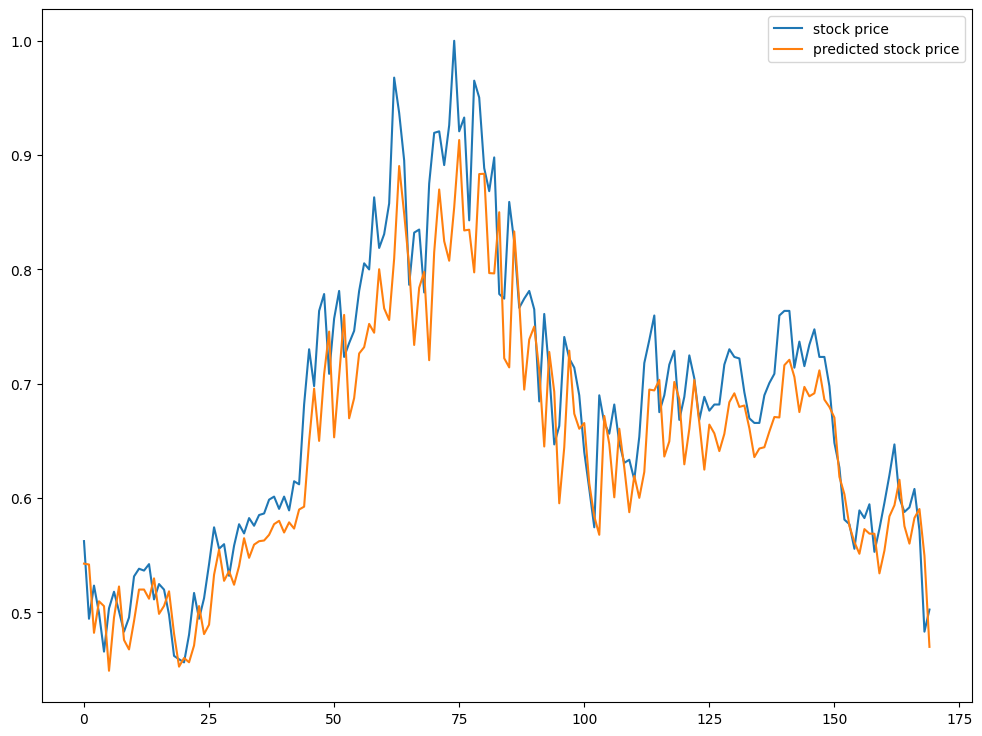

In [17]:
# (9) 그래프 그리기
plt.figure(figsize=(12, 9))
plt.plot(y_test, label='stock price')
plt.plot(pred, label='predicted stock price')
plt.legend()
plt.show()

In [18]:
# window 사이즈 변경 후 순차 훈련 데이터 생성
# 슬라이딩 윈도우 방식을 사용했고 window 가 5으로 해서 동작하게 된다
# 이때 슬라이딩 윈도우 때문에 이전에 test 데이터셋으로 만들거를 그 다음 단계에는 train 데이터셋에 해당 데이터가 일부 사용이 되니까 누수가 발생한다
def make_sample(data, window):
    train = []
    target = []
    for i in range(len(data) - window):
        train.append(data[i:i + window])
        target.append(data[i + window])
    return np.array(train), np.array(target)

X_train, y_train = make_sample(train_data, 5)

In [19]:
model = Sequential()
model.add(SimpleRNN(16,
                    input_shape=(X_train.shape[1], 1),
                    activation='tanh',
                    return_sequences=False)
          )
model.add(Dense(1))

In [20]:
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, epochs=100, batch_size=16)

Epoch 1/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 2.6294e-04
Epoch 2/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.1526e-05
Epoch 3/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.7048e-05
Epoch 4/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.3393e-05
Epoch 5/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.0138e-05
Epoch 6/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.6876e-05
Epoch 7/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.4276e-05
Epoch 8/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.2906e-05
Epoch 9/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.8959e-05
Epoch 10/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.2207e-05
Epoch 11/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.9354e-05
Epoch 12/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 3.8634e-05
Epoch 13/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.8136e-05
Epoch 14/100
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss

In [21]:
# (8) 테스트셋으로 미래 주가 예측
X_test, y_test = make_sample(test_data, 30)
pred = model.predict(X_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step


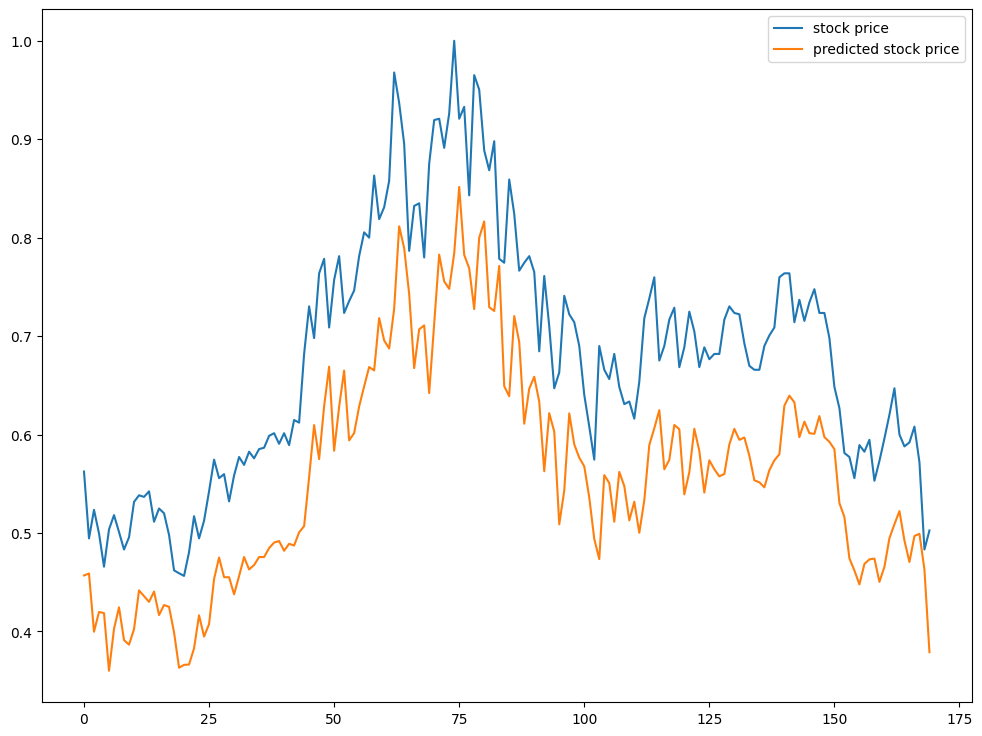

In [22]:
# (9) 그래프 그리기
plt.figure(figsize=(12, 9))
plt.plot(y_test, label='stock price')
plt.plot(pred, label='predicted stock price')
plt.legend()
plt.show()

In [ ]:
# window 사이즈를 줄였더니 정확도가 줄어들었다. 이유는 볼 수 있는 이전 데이터의 양이 줄어들어서 추세를 더 파악하지 못한다고 생각